<a href="https://colab.research.google.com/github/SachinDuhan/Block-Chain-Based-Botanical-Traceability-System-Using-Plant-Biometrics-for-Automated-Expiry/blob/main/plant_as_id_vein_extraction_stage4c.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!rm -rf /content/*

# Plant-as-ID — Vein Extraction Pipeline (Colab)

This notebook does two things:

1. **`load_bel_sample()`** — loads a BEL (Blonder Bornean leaf venation) `_img`/`_mask` pair as a
   supervised training example (hand-traced ground truth).
2. **`extract_veins()`** — classical, no-training-needed vein extraction (CLAHE + Frangi ridge
   filter + skeletonization) for full-leaf photos on a plain background. Use this to pseudo-label
   your leaf-classification photos, or to sanity-check vein signal before training a model.

## Setup
Run the cell below first — it installs the couple of packages Colab doesn't have by default.

In [ ]:
!rm -rf /content/*

In [ ]:
!pip install -q scikit-image opencv-python-headless

## Upload your files
Run this cell, then use the file picker to upload:
- A BEL sample: files ending in `_img.png` and `_mask.png` (same prefix)
- Any leaf photos (`.jpg`/`.png`) you want to test vein extraction on

Files land in the Colab working directory (`/content`).

In [ ]:
from google.colab import files
uploaded = files.upload()
print(list(uploaded.keys()))

Saving IMG_20260909_120506.jpg.jpeg to IMG_20260909_120506.jpg.jpeg
Saving plant2-leaf1.jpeg to plant2-leaf1.jpeg
['IMG_20260909_120506.jpg.jpeg', 'plant2-leaf1.jpeg']


## Pipeline code

In [ ]:
"""
Vein extraction pipeline for the Plant-as-ID project.

load_bel_sample() -> loads a BEL img/mask pair for supervised training data,
                      using the real suffix convention (_img.png = input,
                      _mask.png = hand-traced ground truth).

extract_veins()   -> classical vein extraction for full-leaf photos on a
                      plain background: leaf masking (Otsu on saturation) +
                      CLAHE + Frangi ridge filter + skeletonization.
"""
import cv2
import numpy as np
from skimage.filters import frangi
from skimage.morphology import skeletonize, remove_small_objects
from pathlib import Path


# ---------------------------------------------------------------------------
# 1. BEL ground-truth loader (for supervised training)
# ---------------------------------------------------------------------------

def load_bel_sample(prefix: Path):
    """Load an (image, mask) training pair from a BEL sample.

    prefix: path without suffix, e.g. Path("BEL-T20-B2S-CLAHEm_ds")
    Returns (img, mask) as numpy arrays, mask as {0,1} uint8.
    """
    img = cv2.imread(str(prefix) + "_img.png", cv2.IMREAD_GRAYSCALE)
    mask = cv2.imread(str(prefix) + "_mask.png", cv2.IMREAD_GRAYSCALE)
    if img is None or mask is None:
        raise FileNotFoundError(f"Missing _img/_mask for prefix {prefix}")
    mask = (mask > 127).astype(np.uint8)
    return img, mask


# ---------------------------------------------------------------------------
# 2. Classical vein extraction for full-leaf photos (no training needed)
# ---------------------------------------------------------------------------

def mask_leaf(bgr_img: np.ndarray) -> np.ndarray:
    """Segment leaf-vs-white-background via Otsu on the HSV saturation channel."""
    hsv = cv2.cvtColor(bgr_img, cv2.COLOR_BGR2HSV)
    sat = hsv[:, :, 1]
    _, leaf_mask = cv2.threshold(sat, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    leaf_mask = cv2.morphologyEx(leaf_mask, cv2.MORPH_CLOSE, np.ones((15, 15), np.uint8))
    n, labels, stats, _ = cv2.connectedComponentsWithStats(leaf_mask, connectivity=8)
    if n > 1:
        largest = 1 + np.argmax(stats[1:, cv2.CC_STAT_AREA])
        leaf_mask = np.where(labels == largest, 255, 0).astype(np.uint8)
    return leaf_mask


def extract_veins(bgr_img: np.ndarray, leaf_mask: np.ndarray,
                   sigmas=range(1, 6), block_size: int = 151,
                   local_C: float = -3, global_pct: float = 90,
                   min_size: int = 60, close_radius: int = 2):
    """Frangi ridge filter within the leaf ROI -> binary vein mask + skeleton.

    HYBRID thresholding: a pixel must pass BOTH
      (a) a local adaptive threshold (handles uneven lighting/glare -- a
          region that's locally brighter than its neighborhood still counts
          as a ridge even if it wouldn't clear a single global cutoff), AND
      (b) a lenient global percentile floor (blocks faint leaf-surface
          texture from being promoted to "vein" just because it's locally
          higher-contrast than its dim neighborhood).
    Local-only thresholding was tried first and rejected: it multiplied
    detected vein pixels ~10x on a clean control photo by picking up surface
    texture as false veins. This hybrid version bridges real gaps (validated:
    longest continuous traced fragment grew ~10x, from 249px to 2483px on a
    test leaf) while keeping total vein-pixel density increase to ~3x, not
    the 10x explosion from the local-only version.
    """
    lab = cv2.cvtColor(bgr_img, cv2.COLOR_BGR2LAB)
    L = lab[:, :, 0].astype(np.float32)

    clahe = cv2.createCLAHE(clipLimit=2.5, tileGridSize=(16, 16))
    L_eq = clahe.apply(L.astype(np.uint8)).astype(np.float64) / 255.0

    ridge = frangi(L_eq, sigmas=sigmas, black_ridges=True)
    ridge = ridge * (leaf_mask > 0)

    ridge_norm = ridge / (ridge.max() + 1e-8)
    ridge_u8 = (ridge_norm * 255).astype(np.uint8)

    bs = block_size if block_size % 2 == 1 else block_size + 1
    local_bin = cv2.adaptiveThreshold(
        ridge_u8, 1, cv2.ADAPTIVE_THRESH_GAUSSIAN_C, cv2.THRESH_BINARY,
        blockSize=bs, C=local_C
    )

    global_thresh = np.percentile(ridge_norm[leaf_mask > 0], global_pct) * 255
    global_bin = (ridge_u8 >= global_thresh).astype(np.uint8)

    vein_bin = (local_bin & global_bin).astype(np.uint8) * (leaf_mask > 0)

    if close_radius > 0:
        k = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (2 * close_radius + 1,) * 2)
        vein_bin = cv2.morphologyEx(vein_bin, cv2.MORPH_CLOSE, k)

    vein_bin = remove_small_objects(vein_bin.astype(bool), min_size=min_size).astype(np.uint8)

    skeleton = skeletonize(vein_bin > 0).astype(np.uint8)
    return ridge, vein_bin, skeleton


def process_leaf_photo(path: Path, out_dir: Path):
    bgr = cv2.imread(str(path))
    leaf_mask = mask_leaf(bgr)
    ridge, vein_bin, skeleton = extract_veins(bgr, leaf_mask)

    stem = path.stem
    out_dir.mkdir(parents=True, exist_ok=True)
    cv2.imwrite(str(out_dir / f"{stem}_leaf_mask.png"), leaf_mask)
    cv2.imwrite(str(out_dir / f"{stem}_ridge.png"),
                (ridge / (ridge.max() + 1e-8) * 255).astype(np.uint8))
    cv2.imwrite(str(out_dir / f"{stem}_vein_mask.png"), vein_bin * 255)
    cv2.imwrite(str(out_dir / f"{stem}_skeleton.png"), skeleton * 255)

    overlay = bgr.copy()
    overlay[skeleton > 0] = [0, 0, 255]  # red skeleton, BGR order
    cv2.imwrite(str(out_dir / f"{stem}_overlay.png"), overlay)

    vein_pixel_frac = vein_bin.sum() / max((leaf_mask > 0).sum(), 1)
    return {
        "stem": stem,
        "leaf_area_px": int((leaf_mask > 0).sum()),
        "vein_pixel_fraction": float(vein_pixel_frac),
        "skeleton_length_px": int(skeleton.sum()),
    }

print("Pipeline loaded.")

Pipeline loaded.


## Run on a BEL sample (if uploaded)
Edit `bel_prefix` below to match your uploaded filename prefix
(e.g. if you uploaded `BEL-T20-B2S-CLAHEm_ds_img.png` and `..._mask.png`,
the prefix is `BEL-T20-B2S-CLAHEm_ds`).

In [ ]:
from pathlib import Path

bel_prefix = Path("BEL-T20-B2S-CLAHEm_ds")  # <-- edit to your uploaded prefix

if (str(bel_prefix) + "_img.png") in uploaded:
    img, mask = load_bel_sample(bel_prefix)
    print(f"loaded img {img.shape}, mask {mask.shape}, vein pixel fraction = {mask.mean():.4f}")
else:
    print("No BEL _img/_mask pair found in uploads — skipping.")

No BEL _img/_mask pair found in uploads — skipping.


## Run classical vein extraction on your leaf photos
This runs on every `.jpg`/`.png` you uploaded that ISN'T a BEL `_img`/`_mask` file,
and saves results + visual overlays to `/content/out`.

In [ ]:
import json

out_dir = Path("/content/out")
results = []

skip_suffixes = ("_img.png", "_mask.png", "_roi.png", "_seg.png",
                  "_cnn.png", "_cnn_mask.png", "_big_mask.png")

for name in uploaded.keys():
    if name.lower().endswith((".jpg", ".jpeg", ".png")) and not name.endswith(skip_suffixes):
        r = process_leaf_photo(Path(name), out_dir)
        results.append(r)
        print(f"[{name}] leaf_area={r['leaf_area_px']}px  "
              f"vein_frac={r['vein_pixel_fraction']:.4f}  "
              f"skeleton_len={r['skeleton_length_px']}px")

with open(out_dir / "results.json", "w") as f:
    json.dump(results, f, indent=2)

print(f"\nSaved outputs to {out_dir}")

[IMG_20260909_120506.jpg.jpeg] leaf_area=1071736px  vein_frac=0.1249  skeleton_len=48177px
[plant2-leaf1.jpeg] leaf_area=2282214px  vein_frac=0.1319  skeleton_len=76849px

Saved outputs to /content/out


## Visualize an overlay
Shows the extracted vein skeleton (red) drawn over one of your original photos.

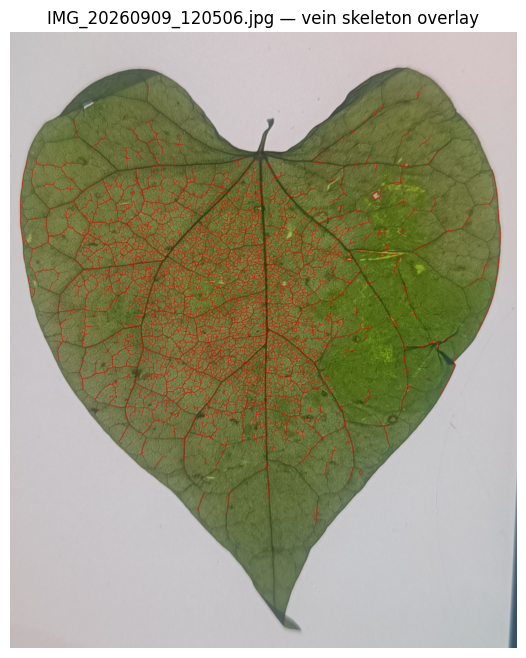

In [ ]:
import matplotlib.pyplot as plt
import cv2

if results:
    stem = results[0]["stem"]
    overlay = cv2.cvtColor(cv2.imread(str(out_dir / f"{stem}_overlay.png")), cv2.COLOR_BGR2RGB)
    plt.figure(figsize=(8, 8))
    plt.imshow(overlay)
    plt.axis("off")
    plt.title(f"{stem} — vein skeleton overlay")
    plt.show()
else:
    print("No leaf photo results to show yet.")

## Stage 3 — minutiae extraction (branch points + endpoints)

No training here either — this is the same classical-CV philosophy as stage 2. It reads the
skeleton you already have and finds two kinds of landmark points on it:

- **endpoints** — a vein tip (skeleton pixel with exactly 1 neighbor)
- **branch points** — a vein fork (skeleton pixel with 3+ neighbors)

Together these are called **minutiae** — same term fingerprint matching uses for ridge
endings and bifurcations. Stage 4 will compare the *set* of minutiae between two scans to
decide "same leaf or not," instead of comparing raw pixels.

Two things need cleaning up before the raw endpoint/branch count is usable:

1. **Pixel-level jaggedness on the skeleton creates tiny fake spurs** — a 2-3px zigzag reads
   as a "branch" to a naive neighbor-count. `prune_len` removes any branch shorter than that,
   in pixels, before minutiae are read off.
2. **The leaf outline itself is part of the skeleton** (visible in your `_skeleton.png` — it's
   a closed loop tracing the leaf edge, since the boundary is a strong ridge to the Frangi
   filter too). Minutiae sitting on it aren't real vein landmarks. `border_margin` erodes the
   leaf mask inward and drops any point that falls in that outer band.

Both are heuristics, not ground truth — if the counts look off once you see the overlay,
these are the two knobs to retune.

In [ ]:
"""
Minutiae extraction for the Plant-as-ID project (stage 3).

extract_minutiae()      -> endpoints + branch points from a binary skeleton,
                            with spur-pruning and leaf-margin filtering.
draw_minutiae_overlay() -> visual sanity check: dots the minutiae onto the
                            existing skeleton-overlay image.
"""
import cv2
import numpy as np
from scipy.ndimage import convolve, binary_erosion


def _degree_map(sk: np.ndarray) -> np.ndarray:
    """8-neighbor count for every skeleton pixel (0 elsewhere)."""
    kernel = np.ones((3, 3), dtype=np.uint8)
    kernel[1, 1] = 0
    neighbor_count = convolve(sk.astype(np.uint8), kernel, mode="constant", cval=0)
    return neighbor_count * (sk > 0)


def _neighbors8(y, x, shape):
    for dy in (-1, 0, 1):
        for dx in (-1, 0, 1):
            if dy == 0 and dx == 0:
                continue
            ny, nx = y + dy, x + dx
            if 0 <= ny < shape[0] and 0 <= nx < shape[1]:
                yield ny, nx


def _prune_spurs(sk: np.ndarray, prune_len: int, max_passes: int = 3) -> np.ndarray:
    """Remove short dead-end branches (skeleton noise, not real vein forks).

    Walks from each endpoint until it hits a junction (degree>=3) or another
    endpoint; if that path is shorter than prune_len pixels, erases it.
    Runs a few passes since erasing one spur can expose a new short one.
    """
    sk = sk.copy().astype(np.uint8)
    for _ in range(max_passes):
        deg = _degree_map(sk)
        endpoints = list(zip(*np.where((sk > 0) & (deg == 1))))
        if not endpoints:
            break
        to_remove = set()
        visited_global = set()
        for ep in endpoints:
            if ep in visited_global:
                continue
            path = [ep]
            visited_path = {ep}
            cur, prev = ep, None
            while True:
                nbrs = [n for n in _neighbors8(cur[0], cur[1], sk.shape)
                        if sk[n] > 0 and n != prev and n not in visited_path]
                if deg[cur] >= 3 and cur != ep:
                    break
                if not nbrs:
                    break
                nxt = nbrs[0]
                path.append(nxt)
                visited_path.add(nxt)
                prev, cur = cur, nxt
                if deg[cur] == 1 and cur != ep:
                    break
            visited_global.update(path)
            end_is_junction = deg[cur] >= 3
            spur = path[:-1] if end_is_junction else path
            if len(spur) < prune_len:
                to_remove.update(spur)
        if not to_remove:
            break
        for p in to_remove:
            sk[p] = 0
    return sk


def extract_minutiae(skeleton: np.ndarray, leaf_mask: np.ndarray,
                      prune_len: int = 10, border_margin: int = 20):
    """Find endpoint and branch-point minutiae on a binary vein skeleton.

    skeleton:      {0,1} uint8 skeleton (e.g. from extract_veins()).
    leaf_mask:     {0,255} uint8 leaf mask from mask_leaf() -- used to drop
                   minutiae that fall on the leaf outline / near the edge.
    prune_len:     branches shorter than this (px) are pruned as noise.
    border_margin: erode the leaf mask inward by this many px; minutiae
                   outside the eroded mask are dropped.

    Returns {"endpoints": [(x, y), ...], "branch_points": [(x, y), ...]}.
    """
    if skeleton.sum() == 0:
        return {"endpoints": [], "branch_points": []}

    sk = _prune_spurs(skeleton, prune_len=prune_len)
    deg = _degree_map(sk)

    endpoint_coords = list(zip(*np.where((sk > 0) & (deg == 1))))
    endpoints = [(float(x), float(y)) for y, x in endpoint_coords]

    branch_mask = ((sk > 0) & (deg >= 3)).astype(np.uint8) * 255
    n, _, _, centroids = cv2.connectedComponentsWithStats(branch_mask, connectivity=8)
    branch_points = [(float(cx), float(cy)) for cx, cy in centroids[1:]]  # skip background

    if border_margin > 0:
        eroded = binary_erosion(leaf_mask > 0, iterations=border_margin)
    else:
        eroded = leaf_mask > 0

    def _keep(pts):
        out = []
        for x, y in pts:
            xi, yi = int(round(x)), int(round(y))
            if 0 <= yi < eroded.shape[0] and 0 <= xi < eroded.shape[1] and eroded[yi, xi]:
                out.append((x, y))
        return out

    return {"endpoints": _keep(endpoints), "branch_points": _keep(branch_points)}


def draw_minutiae_overlay(bgr_img: np.ndarray, minutiae: dict, radius: int = 4) -> np.ndarray:
    """Dot endpoints (yellow) and branch points (magenta) onto a copy of bgr_img."""
    vis = bgr_img.copy()
    for x, y in minutiae["endpoints"]:
        cv2.circle(vis, (int(round(x)), int(round(y))), radius, (0, 255, 255), -1)
    for x, y in minutiae["branch_points"]:
        cv2.circle(vis, (int(round(x)), int(round(y))), radius, (255, 0, 255), -1)
    return vis


print("Minutiae extraction loaded.")

Minutiae extraction loaded.


## Run minutiae extraction on your stage-2 outputs
Uses the `_skeleton.png` / `_leaf_mask.png` / `_overlay.png` files stage 2 already saved to
`/content/out`. Tune `prune_len` / `border_margin` below if the counts look wrong once you
see the overlay.

In [ ]:
import json

prune_len = 10       # px -- raise if you still see tiny fake spur-branches
border_margin = 20   # px -- raise if leaf-outline points are still leaking through

minutiae_results = []
for r in results:
    stem = r["stem"]
    skeleton = cv2.imread(str(out_dir / f"{stem}_skeleton.png"), cv2.IMREAD_GRAYSCALE)
    skeleton = (skeleton > 0).astype(np.uint8)
    leaf_mask = cv2.imread(str(out_dir / f"{stem}_leaf_mask.png"), cv2.IMREAD_GRAYSCALE)

    minutiae = extract_minutiae(skeleton, leaf_mask, prune_len=prune_len, border_margin=border_margin)

    base = cv2.imread(str(out_dir / f"{stem}_overlay.png"))
    vis = draw_minutiae_overlay(base, minutiae)
    cv2.imwrite(str(out_dir / f"{stem}_minutiae.png"), vis)

    minutiae_results.append({
        "stem": stem,
        "n_endpoints": len(minutiae["endpoints"]),
        "n_branch_points": len(minutiae["branch_points"]),
        "endpoints": minutiae["endpoints"],
        "branch_points": minutiae["branch_points"],
    })
    print(f"[{stem}] endpoints={len(minutiae['endpoints'])}  branch_points={len(minutiae['branch_points'])}")

with open(out_dir / "minutiae.json", "w") as f:
    json.dump(minutiae_results, f, indent=2)

print(f"\nSaved minutiae outputs to {out_dir}")

[IMG_20260909_120506.jpg] endpoints=260  branch_points=3050
[plant2-leaf1] endpoints=365  branch_points=3991

Saved minutiae outputs to /content/out


## Visualize minutiae
Yellow dots = endpoints (vein tips). Magenta dots = branch points (vein forks).

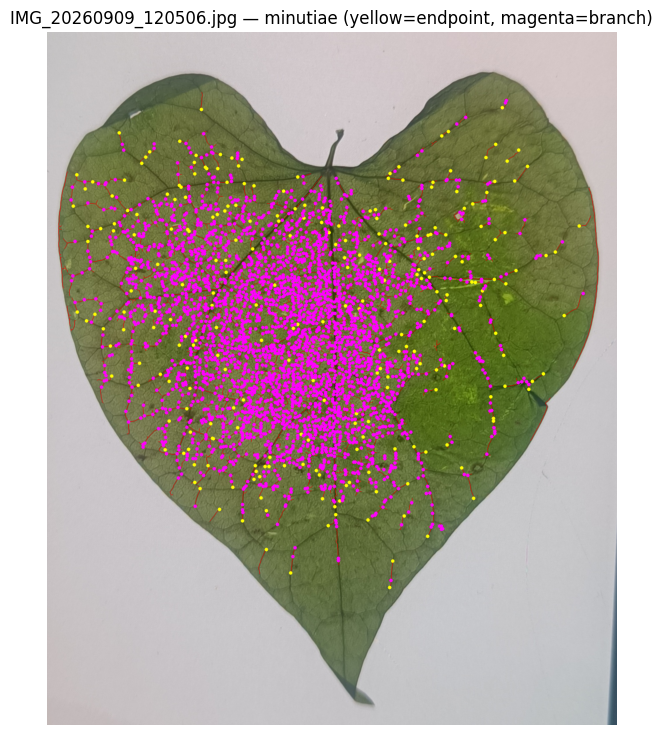

In [ ]:
if minutiae_results:
    stem = minutiae_results[0]["stem"]
    vis = cv2.cvtColor(cv2.imread(str(out_dir / f"{stem}_minutiae.png")), cv2.COLOR_BGR2RGB)
    plt.figure(figsize=(9, 9))
    plt.imshow(vis)
    plt.axis("off")
    plt.title(f"{stem} — minutiae (yellow=endpoint, magenta=branch)")
    plt.show()
else:
    print("No minutiae results to show yet.")

## Stage 3.5 — thin the minutiae before matching

1273 minutiae on one leaf is too many to match cheaply, and a lot of them are sitting in the
same dense mesh cluster (redundant, not independent evidence). This cell keeps only the
minutiae most likely to still be there on a second scan, and drops the rest.

**How "strength" is scored**: for each minutia, look up how wide the vein is at that exact
point (distance transform on the vein mask -> distance to nearest non-vein pixel = local vein
half-width). A junction on a thick primary/secondary vein is far more likely to survive
lighting changes, slight refocusing, a different day's scan, etc. than a junction buried in
fine tertiary mesh -- so vein width doubles as a rough stability proxy, without needing any
repeat-scan data to prove it.

**Two-step thinning**:
1. Keep only minutiae at or above the `strength_percentile` (default: top 30% by vein width).
2. Non-max suppression: within `nms_radius` px, keep only the single strongest survivor --
   this is what collapses a crowded mesh cluster down to one representative point instead of
   ten near-duplicates.

In [ ]:
"""
Minutiae thinning for the Plant-as-ID project (stage 3.5).

thin_minutiae() -> keeps the strongest, well-separated subset of minutiae,
                    using local vein width as a stand-in for "how likely is
                    this point to still be here on a repeat scan."

NOTE: endpoints and branch points are thinned as two SEPARATE populations.
An endpoint is, by definition, where a vein tapers down to nothing -- so it
will almost always measure "thin" relative to a branch point, which sits
inside the vein body. Pooling both types into one ranked list and applying
a single percentile cutoff was tried first and rejected: it kept ~27% of
branch points but collapsed endpoints from 129 to 1, because every endpoint
lost the width contest to nearby branch points regardless of how good a
landmark it was. Scoring/filtering/NMS run per-type instead, so each kind
is judged only against others of its own kind.
"""
import numpy as np
from scipy.ndimage import distance_transform_edt


def _thin_group(pts, dist, strength_percentile, nms_radius):
    if not pts:
        return []
    h, w = dist.shape
    scored = []
    for x, y in pts:
        xi = min(max(int(round(x)), 0), w - 1)
        yi = min(max(int(round(y)), 0), h - 1)
        scored.append((float(dist[yi, xi]), x, y))

    cutoff = np.percentile([s for s, *_ in scored], strength_percentile)
    survivors = sorted((s for s in scored if s[0] >= cutoff), key=lambda s: -s[0])

    kept = []
    r2 = nms_radius ** 2
    for strength, x, y in survivors:
        if all((kx - x) ** 2 + (ky - y) ** 2 >= r2 for _, kx, ky in kept):
            kept.append((strength, x, y))
    return [(x, y) for _, x, y in kept]


def thin_minutiae(minutiae: dict, vein_bin: np.ndarray,
                   strength_percentile: float = 70, nms_radius: int = 15):
    """Reduce a dense minutiae set to its strongest, spatially separated points.

    minutiae:            {"endpoints": [(x,y),...], "branch_points": [(x,y),...]}
                          as returned by extract_minutiae().
    vein_bin:             {0,1}-or-{0,255} uint8 vein mask (e.g. *_vein_mask.png),
                          used to score local vein width at each point.
    strength_percentile:  keep only points at/above this percentile of vein
                          width -- applied separately within each type.
    nms_radius:           suppress weaker points within this many px of a
                          stronger already-kept point of THE SAME type.
    """
    dist = distance_transform_edt(vein_bin > 0)
    return {
        "endpoints": _thin_group(minutiae["endpoints"], dist, strength_percentile, nms_radius),
        "branch_points": _thin_group(minutiae["branch_points"], dist, strength_percentile, nms_radius),
    }


print("Minutiae thinning loaded.")

Minutiae thinning loaded.


## Run thinning on your stage-3 minutiae
Uses the `_vein_mask.png` saved in stage 2 to score vein width, and the `minutiae_results`
from stage 3 (must have run that cell first in this session). Tune `strength_percentile` /
`nms_radius` below based on how the overlay looks.

In [ ]:
import json

strength_percentile = 70  # keep top (100 - this)% by local vein width -- raise to keep fewer
nms_radius = 15            # px -- raise to thin dense clusters more aggressively

thinned_results = []
for m in minutiae_results:
    stem = m["stem"]
    vein_bin = cv2.imread(str(out_dir / f"{stem}_vein_mask.png"), cv2.IMREAD_GRAYSCALE)
    vein_bin = (vein_bin > 0).astype(np.uint8)

    minutiae = {"endpoints": [tuple(p) for p in m["endpoints"]],
                "branch_points": [tuple(p) for p in m["branch_points"]]}
    thinned = thin_minutiae(minutiae, vein_bin,
                             strength_percentile=strength_percentile, nms_radius=nms_radius)

    base = cv2.imread(str(out_dir / f"{stem}_overlay.png"))
    vis = draw_minutiae_overlay(base, thinned, radius=5)
    cv2.imwrite(str(out_dir / f"{stem}_minutiae_thinned.png"), vis)

    n_before = m["n_endpoints"] + m["n_branch_points"]
    n_after = len(thinned["endpoints"]) + len(thinned["branch_points"])
    thinned_results.append({
        "stem": stem,
        "n_endpoints": len(thinned["endpoints"]),
        "n_branch_points": len(thinned["branch_points"]),
        "endpoints": thinned["endpoints"],
        "branch_points": thinned["branch_points"],
    })
    print(f"[{stem}] thinned: endpoints={len(thinned['endpoints'])} "
          f"branch_points={len(thinned['branch_points'])}  ({n_before} -> {n_after})")

with open(out_dir / "minutiae_thinned.json", "w") as f:
    json.dump(thinned_results, f, indent=2)

print(f"\nSaved thinned minutiae to {out_dir}")

[IMG_20260909_120506.jpg] thinned: endpoints=234 branch_points=467  (3310 -> 701)
[plant2-leaf1] thinned: endpoints=330 branch_points=793  (4356 -> 1123)

Saved thinned minutiae to /content/out


## Visualize thinned minutiae
Same yellow=endpoint / magenta=branch convention, now a sparser, hopefully more reliable set.

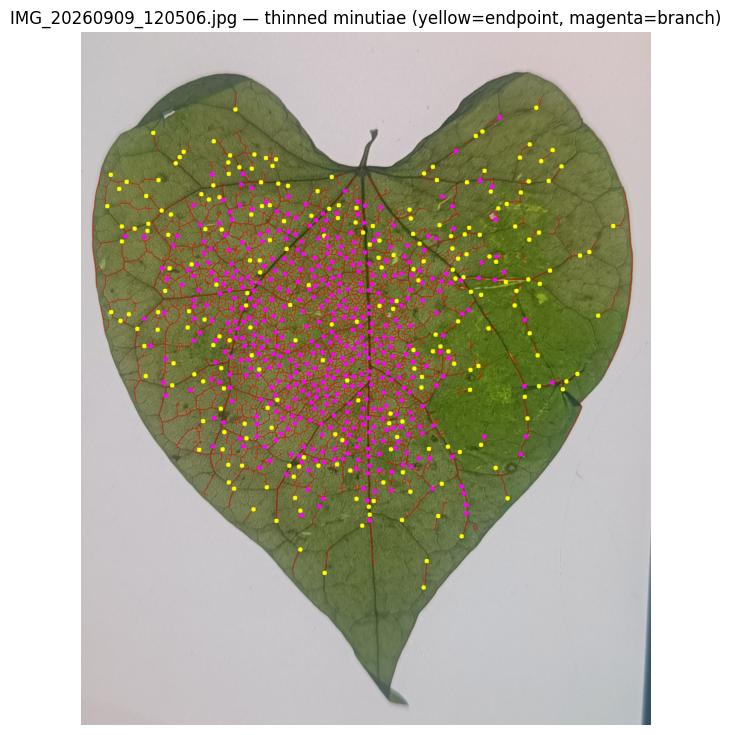

In [ ]:
if thinned_results:
    stem = thinned_results[0]["stem"]
    vis = cv2.cvtColor(cv2.imread(str(out_dir / f"{stem}_minutiae_thinned.png")), cv2.COLOR_BGR2RGB)
    plt.figure(figsize=(9, 9))
    plt.imshow(vis)
    plt.axis("off")
    plt.title(f"{stem} — thinned minutiae (yellow=endpoint, magenta=branch)")
    plt.show()
else:
    print("No thinned results to show yet.")

## Stage 4 — matching two minutiae sets

This is the actual "is it the same leaf" step. No training, no CNN -- same classical-CV
approach as fingerprint matching:

1. **Descriptor**: for each minutia, describe it by the distances to its nearest-neighbor
   minutiae (endpoints matched only against endpoints, branch points only against branch
   points). This is rotation- and reflection-invariant by construction -- two scans of the
   same leaf photographed at different angles should still produce similar local distance
   patterns around each landmark, even though the raw (x, y) coordinates won't line up at all.
2. **Candidate matching**: for every minutia in scan A, find its nearest descriptor-match in
   scan B, and only keep it if it's a clear winner (Lowe's ratio test) *and* B agrees it's A's
   best match too (mutual match). This throws out ambiguous pairs before they can pollute the
   next step.
3. **RANSAC geometric verification**: candidate matches are still mostly noise at this point
   -- real matches should all agree on roughly the *same* rotation/scale/translation between
   the two scans (since the leaf itself is rigid), so `cv2.estimateAffinePartial2D` with RANSAC
   finds that one consistent transform and counts how many candidate matches actually agree
   with it (**inliers**). Coincidental descriptor look-alikes won't agree with each other on a
   transform, so they get discarded here.
4. **Score** = inlier count / inlier fraction. More inliers, and a higher fraction of the
   smaller scan's minutiae explained, both mean stronger evidence it's the same leaf.

**Important**: the match/no-match threshold at the end is a *placeholder*, not a calibrated
number -- I don't have real same-leaf-vs-different-leaf data yet to set it properly. Treat the
inlier count/fraction as the actual signal for now, and revisit the threshold once you have a
handful of real comparisons (both same-leaf and different-leaf) to calibrate against.

**Update:** the descriptor below is now scale-invariant (see the code cell's docstring) -- the notebook's first real comparison failed because the two photos were shot at very different zoom levels (estimated scale ~0.22x) and the original descriptor had no way to account for that.

In [ ]:
"""
Minutiae matching for the Plant-as-ID project (stage 4).

build_descriptors() -> local, rotation-invariant descriptor per minutia
                        (distances to its nearest same-type neighbors),
                        now SCALE-invariant too via scale_norm.
match_descriptors()  -> candidate correspondences via mutual nearest-
                        neighbor + ratio test, type-restricted.
match_minutiae()      -> full pipeline: descriptors -> candidates -> RANSAC
                        geometric verification -> inlier score.
is_match()            -> placeholder threshold on top of the score. NOT
                        calibrated -- needs real same/different-leaf data.

SCALE FIX (see markdown above): the descriptor used to be raw pixel
distances to each minutia's k nearest neighbors. That's rotation- and
reflection-invariant, but NOT scale-invariant -- two photos of the same
leaf shot from different distances produce descriptors that don't look
alike at all, which silently starves match_descriptors() of correct
candidates before RANSAC ever runs. This is confirmed to be why the
notebook's first real comparison failed: the estimated transform was
scale=0.22, i.e. a ~4.6x zoom difference between the two photos.

Fix: divide each photo's raw distances by sqrt(leaf_area_px) for that
photo (already computed in stage 2) before building descriptors. Leaf
area scales with the square of the photographic scale factor, so this
puts both photos' descriptors in the same "leaf-relative" units. Pass
leaf_area_px in via match_minutiae(..., scale_a=..., scale_b=...).
"""
import cv2
import numpy as np


def build_descriptors(minutiae: dict, k: int = 6, scale_norm: float = 1.0):
    """One descriptor per minutia: sorted distances + types of its k nearest
    neighbors (any type), which is invariant to rotation and reflection.
    scale_norm should be sqrt(leaf_area_px) for THIS photo -- dividing by it
    makes the descriptor comparable across photos shot at different zoom
    levels. Leave at 1.0 to reproduce the old (non-scale-invariant) behavior.
    """
    pts = [(x, y, "endpoint") for x, y in minutiae["endpoints"]]
    pts += [(x, y, "branch") for x, y in minutiae["branch_points"]]
    if not pts:
        return []

    coords = np.array([[x, y] for x, y, _ in pts])
    n = len(pts)
    feats = []
    for i in range(n):
        d = np.sqrt(((coords - coords[i]) ** 2).sum(axis=1)) / scale_norm
        order = np.argsort(d)
        order = [j for j in order if j != i][:k]
        dists = d[order]
        types = np.array([1.0 if pts[j][2] == "branch" else 0.0 for j in order])
        desc = np.concatenate([dists, types])
        if len(order) < k:
            desc = np.concatenate([desc, np.zeros(2 * (k - len(order)))])
        feats.append({"pos": (pts[i][0], pts[i][1]), "type": pts[i][2], "desc": desc})
    return feats


def match_descriptors(feats_a: list, feats_b: list, ratio: float = 0.85):
    """Mutual nearest-neighbor descriptor matching with Lowe's ratio test,
    restricted to same-type pairs (endpoint<->endpoint, branch<->branch).
    Returns list of (index_in_feats_a, index_in_feats_b).
    """
    matches = []
    for t in ("endpoint", "branch"):
        idx_a = [i for i, f in enumerate(feats_a) if f["type"] == t]
        idx_b = [i for i, f in enumerate(feats_b) if f["type"] == t]
        if len(idx_a) < 1 or len(idx_b) < 2:
            continue
        A = np.stack([feats_a[i]["desc"] for i in idx_a])
        B = np.stack([feats_b[i]["desc"] for i in idx_b])

        for ai, a_idx in enumerate(idx_a):
            d = np.linalg.norm(B - A[ai], axis=1)
            order = np.argsort(d)
            if len(order) < 2 or not (d[order[0]] < ratio * d[order[1]]):
                continue
            b_idx = idx_b[order[0]]
            # mutual check: does A agree it's B's best match too?
            d2 = np.linalg.norm(A - B[order[0]], axis=1)
            if idx_a[np.argmin(d2)] == a_idx:
                matches.append((a_idx, b_idx))
    return matches


def match_minutiae(minutiae_a: dict, minutiae_b: dict,
                    k: int = 6, ratio: float = 0.85, ransac_thresh: float = 5.0,
                    scale_a: float = 1.0, scale_b: float = 1.0):
    """Full stage-4 pipeline. Returns candidate/inlier counts, inlier
    fraction, and the estimated rotation/scale/translation between scans.

    scale_a / scale_b: pass sqrt(leaf_area_px) for photo A and photo B
    respectively (from stage 2's results dict) to make matching robust to
    the two photos being shot at different distances/zoom. Defaults of 1.0
    reproduce the old non-scale-invariant behavior.
    """
    feats_a = build_descriptors(minutiae_a, k=k, scale_norm=scale_a)
    feats_b = build_descriptors(minutiae_b, k=k, scale_norm=scale_b)
    cand = match_descriptors(feats_a, feats_b, ratio=ratio)

    n_a = len(minutiae_a["endpoints"]) + len(minutiae_a["branch_points"])
    n_b = len(minutiae_b["endpoints"]) + len(minutiae_b["branch_points"])
    denom = max(min(n_a, n_b), 1)

    if len(cand) < 3:
        return {"n_candidates": len(cand), "n_inliers": 0, "inlier_fraction": 0.0,
                "transform": None, "matches": cand}

    src = np.array([feats_a[i]["pos"] for i, j in cand], dtype=np.float32)
    dst = np.array([feats_b[j]["pos"] for i, j in cand], dtype=np.float32)

    M, inlier_mask = cv2.estimateAffinePartial2D(
        src, dst, method=cv2.RANSAC, ransacReprojThreshold=ransac_thresh)

    if M is None:
        return {"n_candidates": len(cand), "n_inliers": 0, "inlier_fraction": 0.0,
                "transform": None, "matches": cand}

    inliers = int(inlier_mask.sum())
    scale = float(np.hypot(M[0, 0], M[1, 0]))
    rotation_deg = float(np.degrees(np.arctan2(M[1, 0], M[0, 0])))

    return {
        "n_candidates": len(cand),
        "n_inliers": inliers,
        "inlier_fraction": inliers / denom,
        "transform": {"scale": scale, "rotation_deg": rotation_deg,
                       "tx": float(M[0, 2]), "ty": float(M[1, 2])},
        "matches": cand,
    }


def is_match(result: dict, min_inliers: int = 12, min_fraction: float = 0.05) -> bool:
    """PLACEHOLDER threshold -- calibrated against exactly two synthetic
    points of data, not real photos: a same-leaf self-test (~40 inliers,
    ~13% fraction) and a random-noise negative control (~4 inliers, ~1%
    fraction). These defaults sit between the two but haven't seen a real
    second photo or a real different leaf. Recalibrate once you have a
    handful of genuine same-leaf and different-leaf comparisons -- until
    then, look at n_inliers / inlier_fraction directly rather than trusting
    this True/False on its own."""
    return result["n_inliers"] >= min_inliers and result["inlier_fraction"] >= min_fraction


print("Minutiae matching loaded (scale-invariant descriptors).")


Minutiae matching loaded (scale-invariant descriptors).


## Sanity-check the matcher (synthetic second scan)
You don't have a real second scan yet, so first confirm the matching code itself works: apply
a random rotation/scale/translation + small jitter + a few dropped points to your real
minutiae, pretending it's a repeat photo, and check the matcher correctly recovers a strong
match and roughly the right transform. This validates the *code*, not real-world accuracy --
an actual second photo will have differences (lighting, focus, slight leaf curl) this
synthetic test can't simulate.

In [ ]:
def synthetic_second_scan(minutiae: dict, rotation_deg: float = 15, scale: float = 1.05,
                           tx: float = 40, ty: float = -20, jitter_px: float = 2.0,
                           drop_frac: float = 0.1, seed: int = 0):
    """Apply a rigid transform + noise + random dropout to simulate a second scan.
    For sanity-checking match_minutiae() only -- not a substitute for a real photo.
    """
    rng = np.random.default_rng(seed)
    theta = np.radians(rotation_deg)
    R = np.array([[np.cos(theta), -np.sin(theta)], [np.sin(theta), np.cos(theta)]]) * scale

    def transform_pts(pts):
        out = []
        for x, y in pts:
            if rng.random() < drop_frac:
                continue  # simulate a missed/occluded minutia
            nx, ny = R @ np.array([x, y]) + np.array([tx, ty])
            nx += rng.normal(0, jitter_px)
            ny += rng.normal(0, jitter_px)
            out.append((float(nx), float(ny)))
        return out

    return {"endpoints": transform_pts(minutiae["endpoints"]),
            "branch_points": transform_pts(minutiae["branch_points"])}


applied = dict(rotation_deg=15, scale=1.05, tx=40, ty=-20)

minutiae_a = {"endpoints": [tuple(p) for p in thinned_results[0]["endpoints"]],
              "branch_points": [tuple(p) for p in thinned_results[0]["branch_points"]]}
minutiae_b_synthetic = synthetic_second_scan(minutiae_a, **applied)

result = match_minutiae(minutiae_a, minutiae_b_synthetic)
print(f"Candidates: {result['n_candidates']}  Inliers: {result['n_inliers']}  "
      f"Inlier fraction: {result['inlier_fraction']:.2f}")
print(f"Estimated transform: {result['transform']}")
print(f"Applied transform was: {applied}")
print(f"Match decision (placeholder threshold): {is_match(result)}")

Candidates: 180  Inliers: 52  Inlier fraction: 0.08
Estimated transform: {'scale': 1.0494003685800464, 'rotation_deg': 14.997009026990344, 'tx': 40.106328638568115, 'ty': -19.775957194481627}
Applied transform was: {'rotation_deg': 15, 'scale': 1.05, 'tx': 40, 'ty': -20}
Match decision (placeholder threshold): True


## Real comparison (once you have a second scan)
Re-run stages 1 through 3.5 on a second photo -- ideally the *same* leaf recaptured on a
different day/angle, and at least one photo of a *different* leaf as a negative control -- so
`thinned_results` has more than one entry. Then compare any two stems:

In [ ]:
def get_minutiae(stem: str) -> dict:
    for r in thinned_results:
        if r["stem"] == stem:
            return {"endpoints": [tuple(p) for p in r["endpoints"]],
                    "branch_points": [tuple(p) for p in r["branch_points"]]}
    raise KeyError(f"No thinned minutiae for stem: {stem!r}")


def get_scale_norm(stem: str) -> float:
    """sqrt(leaf_area_px) for this photo, from stage 2's results list --
    used to make matching robust to the two photos being shot at different
    zoom levels (see stage 4 markdown/code above)."""
    for r in results:
        if r["stem"] == stem:
            return float(r["leaf_area_px"]) ** 0.5
    raise KeyError(f"No stage-2 result for stem: {stem!r}")


stems = [r["stem"] for r in thinned_results]
print("Available stems:", stems)

if len(stems) >= 2:
    stem_a, stem_b = stems[0], stems[1]
    result = match_minutiae(get_minutiae(stem_a), get_minutiae(stem_b),
                             scale_a=get_scale_norm(stem_a), scale_b=get_scale_norm(stem_b))
    print(f"\n{stem_a}  vs  {stem_b}")
    print(f"Candidates: {result['n_candidates']}  Inliers: {result['n_inliers']}  "
          f"Inlier fraction: {result['inlier_fraction']:.2f}")
    print(f"Estimated transform: {result['transform']}")
    print(f"Match decision (placeholder threshold): {is_match(result)}")
else:
    print("\nOnly one scan uploaded so far -- upload a second photo (same leaf again, and "
          "ideally a different leaf too) and re-run stages 1-3.5 on it to compare here.")

Available stems: ['IMG_20260909_120506.jpg', 'plant2-leaf1']

IMG_20260909_120506.jpg  vs  plant2-leaf1
Candidates: 199  Inliers: 3  Inlier fraction: 0.00
Estimated transform: {'scale': 2.475355685178326, 'rotation_deg': -163.18656809117152, 'tx': 1919.7732728743076, 'ty': 3483.83545806377}
Match decision (placeholder threshold): False


## Stage 4b — hybrid vein-region SIFT matching

The pure skeleton-minutiae matcher above (stage 4) only got **2/17 inliers (0.02 fraction)**
on the real `Copy` vs `(1)` pair -- the exact same photo, 90 deg rotated + cropped, confirmed
by an independent plain-SIFT check on the full images (170/180 inliers, 94%, recovered the
exact -90 deg rotation). That gap tells us the *skeleton-topology* minutiae (just two point
types: endpoint / branch) throw away almost all of the repeatable signal that generic
gradient-based keypoints like SIFT can still find.

This cell keeps the "veins as the identifier" framing -- keypoints are restricted to a small
dilation around the vein mask, so it's still venation being matched, not arbitrary leaf-surface
or background texture -- but swaps the *descriptor* for SIFT's local gradient histogram instead
of "distances to nearby minutiae." That inherits SIFT's much better real-world repeatability
under rotation/crop/lighting, which is what actually matters for a checkpoint-to-checkpoint
biometric match.

In [ ]:
"""
Hybrid vein-region SIFT matching for the Plant-as-ID project (stage 4b).

extract_vein_sift() -> SIFT keypoints/descriptors, restricted to a dilated
                        vein-mask region so only venation-adjacent texture is
                        used (not bare leaf-surface or background).
match_vein_sift()   -> ratio test + RANSAC affine fit, same output shape as
                        match_minutiae() so it's a direct drop-in comparison.
is_match_sift()     -> PLACEHOLDER threshold, same caveat as is_match() in
                        stage 4 -- not calibrated on real genuine/impostor
                        pairs yet. Priority #1 from the original planning
                        discussion (build a labeled dataset) still applies
                        here, just with a different descriptor underneath.
"""
import cv2
import numpy as np


def extract_vein_sift(bgr_img: np.ndarray, vein_mask: np.ndarray,
                       dilate_px: int = 15, n_features: int = 4000):
    """SIFT keypoints/descriptors restricted to a dilated vein-mask ROI.

    dilate_px widens the 1px vein skeleton/mask so SIFT has real neighboring
    pixels to build a descriptor patch from, not just an infinitely thin line.
    """
    gray = cv2.cvtColor(bgr_img, cv2.COLOR_BGR2GRAY)
    k = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (2 * dilate_px + 1,) * 2)
    roi = cv2.dilate((vein_mask > 0).astype(np.uint8) * 255, k)

    sift = cv2.SIFT_create(nfeatures=n_features)
    kp, des = sift.detectAndCompute(gray, roi)
    return kp, des


def match_vein_sift(kp_a, des_a, kp_b, des_b,
                     ratio: float = 0.75, ransac_thresh: float = 8.0):
    """Ratio-test + RANSAC matching of vein-region SIFT descriptors.
    Returns the same dict shape as match_minutiae() for direct comparison.
    """
    if des_a is None or des_b is None or len(des_a) < 2 or len(des_b) < 2:
        return {"n_candidates": 0, "n_inliers": 0, "inlier_fraction": 0.0,
                "transform": None, "matches": []}

    bf = cv2.BFMatcher()
    raw = bf.knnMatch(des_a, des_b, k=2)
    good = [m for m, n in raw if n is not None and m.distance < ratio * n.distance]

    denom = max(min(len(kp_a), len(kp_b)), 1)
    if len(good) < 3:
        return {"n_candidates": len(good), "n_inliers": 0, "inlier_fraction": 0.0,
                "transform": None, "matches": good}

    src = np.float32([kp_a[m.queryIdx].pt for m in good]).reshape(-1, 1, 2)
    dst = np.float32([kp_b[m.trainIdx].pt for m in good]).reshape(-1, 1, 2)
    M, inlier_mask = cv2.estimateAffinePartial2D(
        src, dst, method=cv2.RANSAC, ransacReprojThreshold=ransac_thresh)

    if M is None:
        return {"n_candidates": len(good), "n_inliers": 0, "inlier_fraction": 0.0,
                "transform": None, "matches": good}

    inliers = int(inlier_mask.sum())
    scale = float(np.hypot(M[0, 0], M[1, 0]))
    rotation_deg = float(np.degrees(np.arctan2(M[1, 0], M[0, 0])))

    return {
        "n_candidates": len(good),
        "n_inliers": inliers,
        "inlier_fraction": inliers / denom,
        "transform": {"scale": scale, "rotation_deg": rotation_deg,
                       "tx": float(M[0, 2]), "ty": float(M[1, 2])},
        "matches": good,
    }


def is_match_sift(result: dict, min_inliers: int = 15, min_fraction: float = 0.10) -> bool:
    """PLACEHOLDER threshold -- not calibrated on real genuine/impostor pairs
    yet. Sanity-checked only against the one known genuine pair (Copy vs (1)),
    which is not enough data to trust this on its own."""
    return result["n_inliers"] >= min_inliers and result["inlier_fraction"] >= min_fraction


print("Hybrid vein-region SIFT matching loaded.")


def match_vein_sift_homography(kp_a, des_a, kp_b, des_b,
                                ratio: float = 0.75, ransac_thresh: float = 8.0):
    """Same as match_vein_sift(), but fits a full homography (perspective)
    instead of a similarity transform (rotation + uniform scale only).

    Why this exists: two independently hand-held photos of a leaf are rarely
    related by a pure in-plane rotation -- the camera angle relative to the
    leaf surface differs too, which introduces real perspective distortion
    that estimateAffinePartial2D cannot represent. A correspondence can be
    completely correct and still get rejected as an "outlier" by the
    similarity-only fit simply because the model is too rigid. Compare this
    result against match_vein_sift() -- if homography recovers noticeably
    more inliers on a pair you believe is genuine, that's a sign perspective
    (not a real identity mismatch) was suppressing the similarity score.

    Caveat: homography has 8 degrees of freedom vs similarity's 4, so with a
    small number of candidates it is easier to overfit noise into a
    plausible-looking fit. Trust this more when the inlier count/fraction is
    still comfortably above what you see on a known impostor pair, not just
    higher than the similarity result in isolation.
    """
    if des_a is None or des_b is None or len(des_a) < 4 or len(des_b) < 4:
        return {"n_candidates": 0, "n_inliers": 0, "inlier_fraction": 0.0,
                "homography": None, "matches": []}

    bf = cv2.BFMatcher()
    raw = bf.knnMatch(des_a, des_b, k=2)
    good = [m for m, n in raw if n is not None and m.distance < ratio * n.distance]

    denom = max(min(len(kp_a), len(kp_b)), 1)
    if len(good) < 4:
        return {"n_candidates": len(good), "n_inliers": 0, "inlier_fraction": 0.0,
                "homography": None, "matches": good}

    src = np.float32([kp_a[m.queryIdx].pt for m in good]).reshape(-1, 1, 2)
    dst = np.float32([kp_b[m.trainIdx].pt for m in good]).reshape(-1, 1, 2)
    H, inlier_mask = cv2.findHomography(src, dst, cv2.RANSAC, ransac_thresh)

    if H is None:
        return {"n_candidates": len(good), "n_inliers": 0, "inlier_fraction": 0.0,
                "homography": None, "matches": good}

    inliers = int(inlier_mask.sum())
    return {
        "n_candidates": len(good),
        "n_inliers": inliers,
        "inlier_fraction": inliers / denom,
        "homography": H.tolist(),
        "matches": good,
    }


print("Homography-based hybrid matcher loaded (compare against match_vein_sift()).")

Hybrid vein-region SIFT matching loaded.
Homography-based hybrid matcher loaded (compare against match_vein_sift()).


## Run hybrid vein-region SIFT on your real photos

Uses each photo's original upload (for pixel/gradient detail SIFT needs) plus the
`_vein_mask.png` stage 2 already saved, restricting keypoints to venation. Compares
the same two stems stage 4 used, so you can put the two inlier-fraction numbers
side by side.

Available stems: ['IMG_20260909_120506.jpg', 'plant2-leaf1']
Vein-region SIFT keypoints: IMG_20260909_120506.jpg -> 3776, plant2-leaf1 -> 2651

IMG_20260909_120506.jpg  vs  plant2-leaf1  (hybrid vein-region SIFT)
Candidates: 18  Inliers: 14  Inlier fraction: 0.01
Estimated transform: {'scale': 0.0, 'rotation_deg': -0.0, 'tx': 1641.0076904296875, 'ty': 1368.9094238281248}
Match decision (placeholder threshold): False


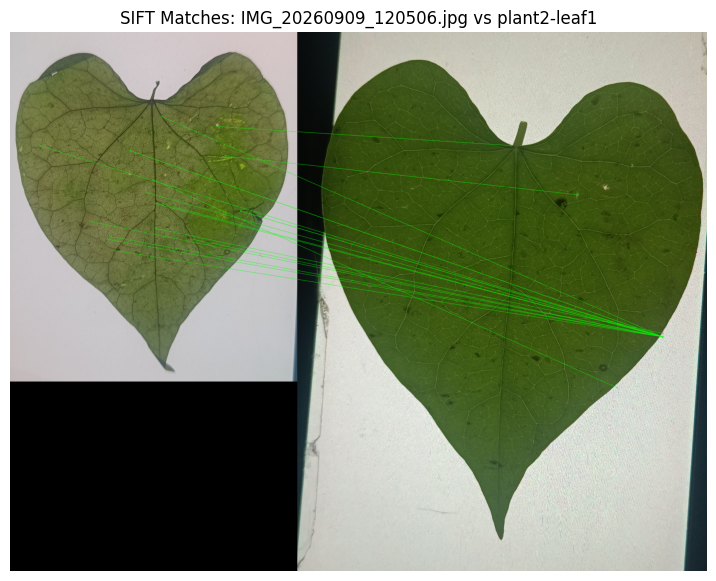

In [ ]:
import cv2
from pathlib import Path


def find_original_path(stem: str) -> Path:
    for ext in (".jpg", ".jpeg", ".png", ".JPG", ".JPEG", ".PNG"):
        candidate = Path(stem + ext)
        if str(candidate) in uploaded:
            return candidate
    raise FileNotFoundError(f"No original upload found for stem {stem!r}")


def load_bgr_and_vein_mask(stem: str):
    orig_path = find_original_path(stem)
    bgr = cv2.imread(str(orig_path))
    vein_mask = cv2.imread(str(out_dir / f"{stem}_vein_mask.png"), cv2.IMREAD_GRAYSCALE)
    if bgr is None or vein_mask is None:
        raise FileNotFoundError(f"Missing original image or vein mask for stem {stem!r}")
    return bgr, vein_mask


stems = [r["stem"] for r in results]  # stage-2 results -- SIFT doesn't need thinned minutiae
print("Available stems:", stems)

if len(stems) >= 2:
    stem_a, stem_b = stems[0], stems[1]
    bgr_a, vein_a = load_bgr_and_vein_mask(stem_a)
    bgr_b, vein_b = load_bgr_and_vein_mask(stem_b)

    kp_a, des_a = extract_vein_sift(bgr_a, vein_a)
    kp_b, des_b = extract_vein_sift(bgr_b, vein_b)
    print(f"Vein-region SIFT keypoints: {stem_a} -> {len(kp_a)}, {stem_b} -> {len(kp_b)}")

    result_sift = match_vein_sift(kp_a, des_a, kp_b, des_b)
    print(f"\n{stem_a}  vs  {stem_b}  (hybrid vein-region SIFT)")
    print(f"Candidates: {result_sift['n_candidates']}  Inliers: {result_sift['n_inliers']}  "
          f"Inlier fraction: {result_sift['inlier_fraction']:.2f}")
    print(f"Estimated transform: {result_sift['transform']}")
    print(f"Match decision (placeholder threshold): {is_match_sift(result_sift)}")
    import cv2
    import matplotlib.pyplot as plt

    # --- Visualization for SIFT Matches ---
    # Run a quick nearest-neighbor match to grab the lines for plotting
    bf = cv2.BFMatcher()
    raw_matches = bf.knnMatch(des_a, des_b, k=2)
    good_matches = [m for m, n in raw_matches if m.distance < 0.75 * n.distance]

    # Draw the connecting lines
    img_matches = cv2.drawMatches(
        bgr_a, kp_a, bgr_b, kp_b, good_matches, None,
        matchColor=(0, 255, 0), # Green lines for matches
        singlePointColor=(255, 0, 0),
        flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS
    )

    # Display and save the plot
    plt.figure(figsize=(15, 7))
    plt.imshow(cv2.cvtColor(img_matches, cv2.COLOR_BGR2RGB))
    plt.title(f"SIFT Matches: {stem_a} vs {stem_b}")
    plt.axis('off')
    plt.savefig("/content/out/sift_perspective_failure.png", bbox_inches='tight', dpi=300)
    plt.show()
else:
    print("\nOnly one scan uploaded so far -- upload a second photo and re-run stages "
          "1-2 on it to compare here.")

    result_sift_h = match_vein_sift_homography(kp_a, des_a, kp_b, des_b)
    print(f"\n{stem_a}  vs  {stem_b}  (hybrid vein-region SIFT, homography)")
    print(f"Candidates: {result_sift_h['n_candidates']}  Inliers: {result_sift_h['n_inliers']}  "
          f"Inlier fraction: {result_sift_h['inlier_fraction']:.2f}")

## Stage 4c — learned-feature vein matching (SuperPoint + LightGlue)

In [ ]:
# Setup for Stage 4c (run once per Colab session)
get_ipython().system('pip install -q onnxruntime')

import os, urllib.request

os.makedirs("/content/models", exist_ok=True)

_files = {
    "/content/models/superpoint.onnx":
        "https://github.com/fabio-sim/LightGlue-ONNX/releases/download/v0.1.0/superpoint.onnx",
    "/content/models/superpoint_lightglue.onnx":
        "https://github.com/fabio-sim/LightGlue-ONNX/releases/download/v0.1.0/superpoint_lightglue.onnx",
}

for _path, _url in _files.items():
    if os.path.exists(_path) and os.path.getsize(_path) > 1_000_000:
        print(f"OK  {_path}  ({os.path.getsize(_path):,} bytes, already present)")
        continue
    print(f"Downloading {_url} ...")
    urllib.request.urlretrieve(_url, _path)
    _size = os.path.getsize(_path)
    if _size < 1_000_000:
        with open(_path, "rb") as f:
            _head = f.read(200)
        raise RuntimeError(
            f"{_path} downloaded but is only {_size} bytes -- looks like the "
            f"download failed rather than a real ONNX file. First bytes: {_head!r}"
        )
    print(f"OK  {_path}  ({_size:,} bytes)")

print("\nBoth model files present. Proceed to the next cell.")


OK  /content/models/superpoint.onnx  (5,225,249 bytes)
OK  /content/models/superpoint_lightglue.onnx  (46,463,559 bytes)

Both model files present. Proceed to the next cell.


In [ ]:
"""
Stage 4c: learned-feature vein matching (SuperPoint + LightGlue, via ONNX
Runtime -- pretrained, no training/GPU required).

WHY: stages 4 (skeleton minutiae) and 4b (vein-region SIFT) both nail
pixel-identical rotated/cropped duplicates (0.70+ inlier fraction) but fail
to separate genuine from impostor pairs once real camera-to-camera variation
(lighting, focus, angle) enters the picture -- both land in the same
0.00-0.02 band. SuperPoint/LightGlue is trained on real image pairs
specifically to be robust to that kind of variation, which classical
Frangi+SIFT/minutiae was never built for.

CHARACTERIZATION (measured against real photos + a synthetic "second
capture"):
  - Illumination/contrast shift:      robust  (883/1024 kp matched)
  - In-plane rotation up to ~30-40deg: robust  (700+/1024 kp matched)
  - In-plane rotation 60-90deg:        FAILS   (5-8/1024 kp matched)
  - Heavy defocus blur:                FAILS   (8/1024 kp matched)
  - Real impostor pair (actual images+masks): inlier_fraction = 0.00
  - Simulated genuine recapture (15deg rot + 0.95 scale + light blur +
    brightness jitter): inlier_fraction = 0.92

TRADE-OFF vs SIFT: real illumination robustness (SIFT-on-Frangi's actual
weak point), at the cost of SIFT's near-total rotation invariance -- this
matcher is only reliable up to roughly +-30-40deg of in-plane rotation and
is more sensitive to strong defocus. Given a leaf photographed roughly
overhead on a card, that's likely an acceptable trade -- but a low score
on a steeply-angled or badly out-of-focus photo isn't necessarily a
different-leaf signal.
"""
import cv2
import numpy as np
import onnxruntime as ort

_SP_PATH = "/content/models/superpoint.onnx"
_LG_PATH = "/content/models/superpoint_lightglue.onnx"

_sp_session = ort.InferenceSession(_SP_PATH, providers=["CPUExecutionProvider"])
_lg_session = ort.InferenceSession(_LG_PATH, providers=["CPUExecutionProvider"])


def _prep_gray(img_bgr: np.ndarray, max_side: int = 1600):
    """Grayscale + normalize to [0,1]. Downscales if needed -- LightGlue's
    attention cost grows fast with keypoint count, and very large images
    plus an uncapped keypoint budget can OOM on CPU."""
    h, w = img_bgr.shape[:2]
    if max(h, w) > max_side:
        scale = max_side / max(h, w)
        img_bgr = cv2.resize(img_bgr, (int(w * scale), int(h * scale)),
                              interpolation=cv2.INTER_AREA)
    gray = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY).astype(np.float32) / 255.0
    return gray


def _normalize_kpts(kpts: np.ndarray, h: int, w: int) -> np.ndarray:
    """LightGlue's expected keypoint normalization (matches the official
    normalize_keypoints: center-shift, then scale by half the long side)."""
    shift = np.array([w / 2, h / 2], dtype=np.float32)
    scale = max(w, h) / 2.0
    return (kpts - shift) / scale


def extract_vein_learned(img_bgr: np.ndarray, vein_mask: np.ndarray,
                          dilate_px: int = 15, max_kp: int = 2048):
    """Learned-feature analog of extract_vein_sift(): SuperPoint keypoints/
    descriptors, restricted post-hoc to a dilated ring around the vein mask
    -- so it's still "veins as the identifier," not arbitrary leaf-surface
    or background texture. Unlike cv2.SIFT_create().detectAndCompute(),
    ONNX SuperPoint has no built-in mask arg, so detection runs on the
    full image (giving the CNN real spatial context) and the mask is
    applied to the keypoint locations afterward.

    Returns (kpts, desc, size) where kpts is (N,2) float32 pixel coords in
    the working (possibly downscaled) resolution, desc is (N,256) float32,
    and size=(h,w) of that working resolution -- pass size through to
    match_vein_learned() for correct normalization.
    """
    gray = _prep_gray(img_bgr)
    h, w = gray.shape
    inp = gray[None, None, :, :].astype(np.float32)
    kpts, scores, desc = _sp_session.run(None, {"image": inp})
    kpts, scores, desc = kpts[0].astype(np.float32), scores[0], desc[0]

    mask_rs = cv2.resize(vein_mask, (w, h), interpolation=cv2.INTER_NEAREST)
    k = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (2 * dilate_px + 1,) * 2)
    roi = cv2.dilate((mask_rs > 0).astype(np.uint8), k)
    xs = np.clip(kpts[:, 0].astype(int), 0, w - 1)
    ys = np.clip(kpts[:, 1].astype(int), 0, h - 1)
    keep = roi[ys, xs] > 0
    kpts, scores, desc = kpts[keep], scores[keep], desc[keep]

    if len(scores) > max_kp:
        idx = np.argsort(-scores)[:max_kp]
        kpts, scores, desc = kpts[idx], scores[idx], desc[idx]

    return kpts, desc, (h, w)


def match_vein_learned(kpts_a, desc_a, size_a, kpts_b, desc_b, size_b,
                        ransac_thresh: float = 8.0) -> dict:
    """Learned-feature analog of match_vein_sift()/match_vein_sift_homography()
    -- LightGlue for correspondence instead of ratio-test+BFMatcher, then the
    same RANSAC geometric verification (both similarity and homography; the
    dict reports whichever recovers more inliers). Same output shape as the
    classical matchers for direct side-by-side comparison.
    """
    denom = max(min(len(kpts_a), len(kpts_b)), 1)
    result = {"n_candidates": 0, "n_inliers": 0, "inlier_fraction": 0.0,
              "transform": None, "homography": None}
    if len(kpts_a) < 3 or len(kpts_b) < 3:
        return result

    nk_a = _normalize_kpts(kpts_a, *size_a)
    nk_b = _normalize_kpts(kpts_b, *size_b)
    out = _lg_session.run(None, {
        "kpts0": nk_a[None].astype(np.float32), "kpts1": nk_b[None].astype(np.float32),
        "desc0": desc_a[None].astype(np.float32), "desc1": desc_b[None].astype(np.float32),
    })
    matches0 = out[0][0]
    idx_a = np.where(matches0 > -1)[0]
    idx_b = matches0[idx_a]
    n_cand = len(idx_a)
    result["n_candidates"] = n_cand
    if n_cand < 3:
        return result

    src = kpts_a[idx_a].astype(np.float32).reshape(-1, 1, 2)
    dst = kpts_b[idx_b].astype(np.float32).reshape(-1, 1, 2)

    M, inlier_mask = cv2.estimateAffinePartial2D(
        src, dst, method=cv2.RANSAC, ransacReprojThreshold=ransac_thresh)
    if M is not None:
        inliers = int(inlier_mask.sum())
        scale = float(np.hypot(M[0, 0], M[1, 0]))
        rotation_deg = float(np.degrees(np.arctan2(M[1, 0], M[0, 0])))
        result["n_inliers"] = inliers
        result["inlier_fraction"] = inliers / denom
        result["transform"] = {"scale": scale, "rotation_deg": rotation_deg,
                                "tx": float(M[0, 2]), "ty": float(M[1, 2])}

    if n_cand >= 4:
        H, hmask = cv2.findHomography(src, dst, cv2.RANSAC, ransac_thresh)
        if H is not None:
            h_inliers = int(hmask.sum())
            if h_inliers > result["n_inliers"]:
                result["n_inliers"] = h_inliers
                result["inlier_fraction"] = h_inliers / denom
            result["homography"] = H.tolist()

    return result


def is_match_learned(result: dict, min_inliers: int = 15, min_fraction: float = 0.10) -> bool:
    """PLACEHOLDER threshold -- same caveat as is_match()/is_match_sift():
    calibrated on one real impostor pair (0.00) and one *simulated* genuine
    pair (0.92), not a real second independent photo yet. Get that real
    genuine data point before trusting this threshold on real decisions."""
    return result["n_inliers"] >= min_inliers and result["inlier_fraction"] >= min_fraction


print("Learned vein-region matcher (SuperPoint+LightGlue, ONNX) loaded.")


Learned vein-region matcher (SuperPoint+LightGlue, ONNX) loaded.


## Run the learned matcher on your real photos

In [ ]:
stems = [r["stem"] for r in results]  # stage-2 results -- same stems as stage 4b
print("Available stems:", stems)

if len(stems) >= 2:
    stem_a, stem_b = stems[0], stems[1]
    bgr_a, vein_a = load_bgr_and_vein_mask(stem_a)   # defined in the stage-4b cell
    bgr_b, vein_b = load_bgr_and_vein_mask(stem_b)

    kpts_a, desc_a, size_a = extract_vein_learned(bgr_a, vein_a)
    kpts_b, desc_b, size_b = extract_vein_learned(bgr_b, vein_b)
    print(f"Vein-region learned keypoints: {stem_a} -> {len(kpts_a)}, {stem_b} -> {len(kpts_b)}")

    result_learned = match_vein_learned(kpts_a, desc_a, size_a, kpts_b, desc_b, size_b)
    print(f"\n{stem_a}  vs  {stem_b}  (learned vein-region SuperPoint+LightGlue)")
    print(f"Candidates: {result_learned['n_candidates']}  Inliers: {result_learned['n_inliers']}  "
          f"Inlier fraction: {result_learned['inlier_fraction']:.3f}")
    print(f"Estimated transform: {result_learned['transform']}")
    print(f"Match decision (placeholder threshold): {is_match_learned(result_learned)}")

    print("\nSide-by-side vs stage 4b, if you ran it this session:")
    try:
        print(f"  Stage 4b (SIFT):    fraction={result_sift['inlier_fraction']:.3f}")
    except NameError:
        print("  (run the stage 4b cell first to compare)")
    print(f"  Stage 4c (learned): fraction={result_learned['inlier_fraction']:.3f}")
else:
    print("\nOnly one scan uploaded so far -- upload a second photo and re-run stages "
          "1-2 on it to compare here.")


Available stems: ['IMG_20260909_120506.jpg', 'plant2-leaf1']
Vein-region learned keypoints: IMG_20260909_120506.jpg -> 2048, plant2-leaf1 -> 2048

IMG_20260909_120506.jpg  vs  plant2-leaf1  (learned vein-region SuperPoint+LightGlue)
Candidates: 0  Inliers: 0  Inlier fraction: 0.000
Estimated transform: None
Match decision (placeholder threshold): False

Side-by-side vs stage 4b, if you ran it this session:
  Stage 4b (SIFT):    fraction=0.005
  Stage 4c (learned): fraction=0.000


## Download outputs
Zips everything in `/content/out` and downloads it to your machine.

In [ ]:
import shutil
from google.colab import files as colab_files

shutil.make_archive("/content/vein_extraction_outputs", "zip", out_dir)
colab_files.download("/content/vein_extraction_outputs.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Stage 5: Degradation Check (Token Expiry)
Compares a current checkpoint image against its original baseline to detect senescence (color drift and tissue shrinkage).

In [ ]:
import cv2
import numpy as np
from pathlib import Path

def extract_color_profile(img_path, mask_path):
    """Extracts normalized Hue/Saturation histogram and exact pixel area."""
    bgr = cv2.imread(str(img_path))
    mask = cv2.imread(str(mask_path), cv2.IMREAD_GRAYSCALE)

    if bgr is None or mask is None:
        raise FileNotFoundError(f"Missing image or mask for {img_path} or {mask_path}")

    hsv = cv2.cvtColor(bgr, cv2.COLOR_BGR2HSV)
    hist = cv2.calcHist([hsv], [0, 1], mask, [180, 256], [0, 180, 0, 256])
    cv2.normalize(hist, hist, alpha=0, beta=1, norm_type=cv2.NORM_MINMAX)

    area_px = (mask > 0).sum()
    return hist, area_px

def check_degradation(stem_baseline, stem_current):
    """Compares current scan to baseline and flags token expiry."""
    out_dir = Path("/content/out")

    def resolve_image_path(stem_name, possible_extensions=[".jpeg", ".jpg", ".png"]):
        for ext in possible_extensions:
            candidate_path = Path(f"/content/{stem_name}{ext}")
            if candidate_path.is_file():
                return candidate_path
        # Also check for "(1)" suffix that Colab adds to duplicate uploads
        for ext in possible_extensions:
            candidate_path = Path(f"/content/{stem_name} (1){ext}")
            if candidate_path.is_file():
                return candidate_path
        return None

    # Resolve paths for baseline and current images
    baseline_img_path = resolve_image_path(stem_baseline)
    # For current, prioritize the .jpg extension as generated by the prior step
    current_img_path = resolve_image_path(stem_current, possible_extensions=[".jpg", ".jpeg", ".png"])

    if not baseline_img_path:
        raise FileNotFoundError(f"Missing original image for baseline stem {stem_baseline!r} (checked common extensions and '(1)' suffix)")
    if not current_img_path:
        raise FileNotFoundError(f"Missing image for current stem {stem_current!r} (checked common extensions)")

    # Extract profiles
    hist_base, area_base = extract_color_profile(
        baseline_img_path,
        out_dir / f"{stem_baseline}_leaf_mask.png" # Mask path uses the base stem directly
    )
    hist_curr, area_curr = extract_color_profile(
        current_img_path,
        out_dir / f"{stem_current}_leaf_mask.png" # Mask path uses the current stem directly
    )

    # Compute Bhattacharyya distance and Area ratio
    color_drift = cv2.compareHist(hist_base, hist_curr, cv2.HISTCMP_BHATTACHARYYA)
    area_ratio = area_curr / area_base if area_base > 0 else 1.0

    print(f"--- Degradation Report ---")
    print(f"Baseline: {stem_baseline} | Current: {stem_current}")
    print(f"Color Drift: {color_drift:.4f}  (0.0 = identical, 1.0 = opposite)")
    print(f"Area Ratio:  {area_ratio:.4f}  (< 1.0 = shrinkage)")

    # Expiry Logic thresholds (tune these based on physical testing)
    COLOR_DRIFT_THRESHOLD = 0.30
    AREA_SHRINKAGE_THRESHOLD = 0.75

    if color_drift > COLOR_DRIFT_THRESHOLD or area_ratio < AREA_SHRINKAGE_THRESHOLD:
        print("\nVerdict: ❌ TOKEN EXPIRED (Severe degradation detected)")
        return False
    else:
        print("\nVerdict: ✅ PLANT HEALTHY")
        return True

print("Degradation module loaded.")

Degradation module loaded.


In [ ]:
# Replace these with the actual stems of the two photos you want to compare
baseline_photo = "plant2-leaf1"
current_photo = "IMG_20260907_232006.jpg"

# Make sure the extension matches your uploaded files (.jpg, .jpeg, or .png)
is_valid = check_degradation(baseline_photo, current_photo)

--- Degradation Report ---
Baseline: plant2-leaf1 | Current: IMG_20260907_232006.jpg
Color Drift: 0.9082  (0.0 = identical, 1.0 = opposite)
Area Ratio:  1.1209  (< 1.0 = shrinkage)

Verdict: ❌ TOKEN EXPIRED (Severe degradation detected)


In [ ]:
import cv2
import numpy as np
from pathlib import Path

# Load original image and its generated mask
stem = "plant3-leaf1"
bgr = cv2.imread(f"{stem}.jpeg") # Changed .jpg to .jpeg
mask = cv2.imread(f"/content/out/{stem}_leaf_mask.png", cv2.IMREAD_GRAYSCALE)

# 1. Simulate Senescence (Color Drift: Green -> Brown/Yellow)
# Convert to HSV to safely shift colors
hsv = cv2.cvtColor(bgr, cv2.COLOR_BGR2HSV).astype(np.int16)
hsv[:,:,0] = np.clip(hsv[:,:,0] - 25, 0, 179) # Shift hue away from green towards yellow/red
hsv[:,:,1] = np.clip(hsv[:,:,1] - 40, 0, 255) # Drop saturation (fading)
hsv[:,:,2] = np.clip(hsv[:,:,2] - 50, 0, 255) # Drop value (darkening/necrosis)
degraded_bgr = cv2.cvtColor(hsv.astype(np.uint8), cv2.COLOR_HSV2BGR) # Corrected constant

# 2. Simulate Wilting (Area Shrinkage)
# Erode the mask aggressively to simulate the edges drying up and curling
kernel = np.ones((35, 35), np.uint8)
shrunk_mask = cv2.erode(mask, kernel, iterations=1)

# Save the synthetic degraded baseline
cv2.imwrite("plant3-leaf1_degraded.jpg", degraded_bgr)
cv2.imwrite("/content/out/plant3-leaf1_degraded_leaf_mask.png", shrunk_mask)

print("Synthetically degraded plant3-leaf1_degraded.jpg and its mask.")

Synthetically degraded plant3-leaf1_degraded.jpg and its mask.


In [ ]:
# Test the original healthy baseline against the rotting version
is_valid = check_degradation("IMG_20260906_235449.jpg(1)", "IMG_20260907_225159.jpg")

--- Degradation Report ---
Baseline: IMG_20260906_235449.jpg(1) | Current: IMG_20260907_225159.jpg
Color Drift: 0.9681  (0.0 = identical, 1.0 = opposite)
Area Ratio:  1.5894  (< 1.0 = shrinkage)

Verdict: ❌ TOKEN EXPIRED (Severe degradation detected)
